# Notebook 02: Visualización exploratoria
**Proyecto final: emisiones de CO₂ per cápita (Our World in Data)** · Responsable: Julian

Este notebook usa los datos que dejó el notebook 01 (`../data/co2_limpio_2019.csv`) y el dataset completo para las series de tiempo.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

AZUL = "#2a6fbb"      # color principal de datos
GRIS = "#8a8f98"      # contexto / comparaciones
ROJO = "#c8452f"      # resaltar un caso o la recta del modelo
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10,
})

ANIO = 2019   # mismo año de análisis que el notebook 01

df = pd.read_csv("../data/owid-co2-data.csv")          # dataset completo (series de tiempo)
limpio = pd.read_csv("../data/co2_limpio_2019.csv")    # países con datos completos en ANIO (salida del notebook 01)
print(f"Dataset completo: {df.shape[0]:,} filas | Dataset limpio: {limpio.shape[0]} países")

Matplotlib is building the font cache; this may take a moment.


Dataset completo: 56,269 filas | Dataset limpio: 164 países


Antes de modelar, se visualizan los datos para entender qué patrones existen.

## 2.1 Evolución de las emisiones mundiales

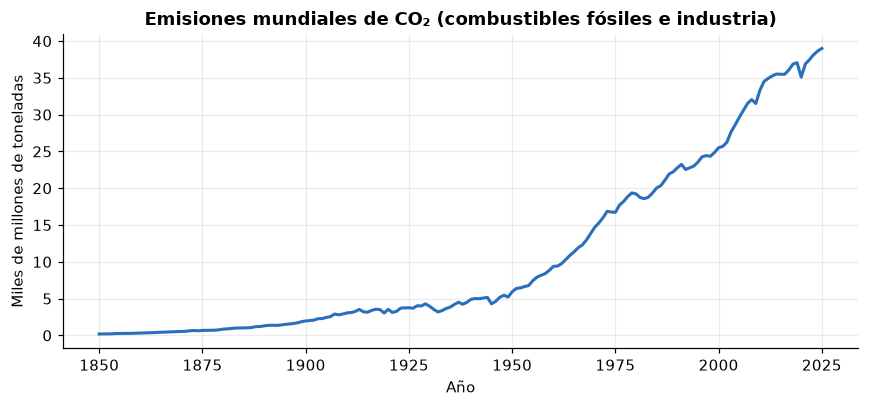

In [2]:
mundo = df[df["country"] == "World"].dropna(subset=["co2"])
mundo = mundo[mundo["year"] >= 1850]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(mundo["year"], mundo["co2"] / 1000, color=AZUL, lw=2)
ax.set_title("Emisiones mundiales de CO₂ (combustibles fósiles e industria)")
ax.set_ylabel("Miles de millones de toneladas")
ax.set_xlabel("Año")
plt.tight_layout(); plt.show()

## 2.2 ¿Quién emite más? Total frente a per cápita

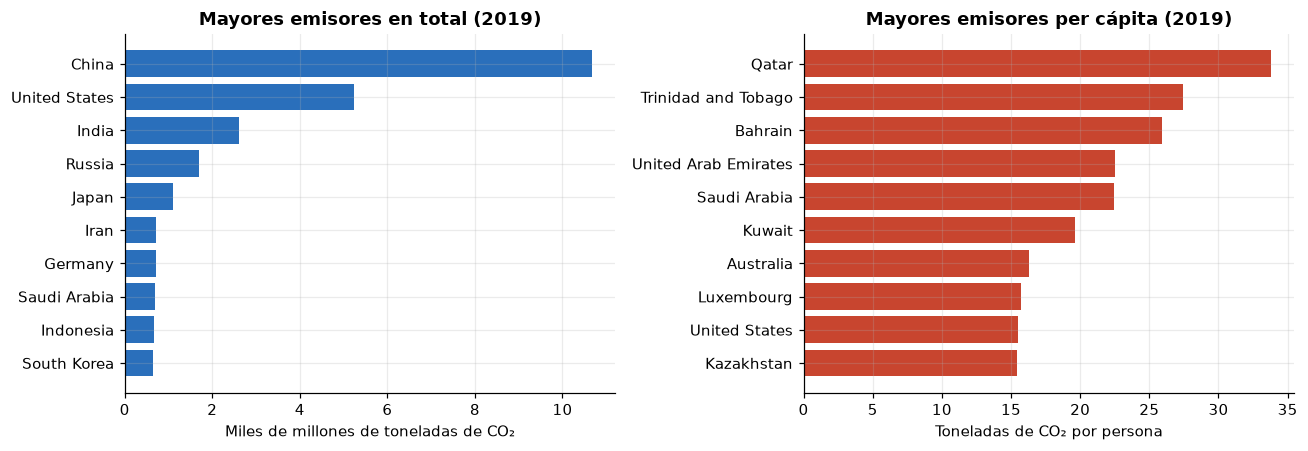

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

top_total = limpio.nlargest(10, "co2").sort_values("co2")
axes[0].barh(top_total["country"], top_total["co2"] / 1000, color=AZUL)
axes[0].set_title(f"Mayores emisores en total ({ANIO})")
axes[0].set_xlabel("Miles de millones de toneladas de CO₂")

top_pc = limpio.nlargest(10, "co2_per_capita").sort_values("co2_per_capita")
axes[1].barh(top_pc["country"], top_pc["co2_per_capita"], color=ROJO)
axes[1].set_title(f"Mayores emisores per cápita ({ANIO})")
axes[1].set_xlabel("Toneladas de CO₂ por persona")

plt.tight_layout(); plt.show()

**Lectura:** el ranking cambia por completo. En total emiten más los países grandes (China, Estados Unidos, India); por persona, destacan productores de petróleo y gas con poca población. Por eso el análisis se hace **per cápita**: permite comparar países de tamaños muy distintos.

## 2.3 Colombia frente a otros países de la región

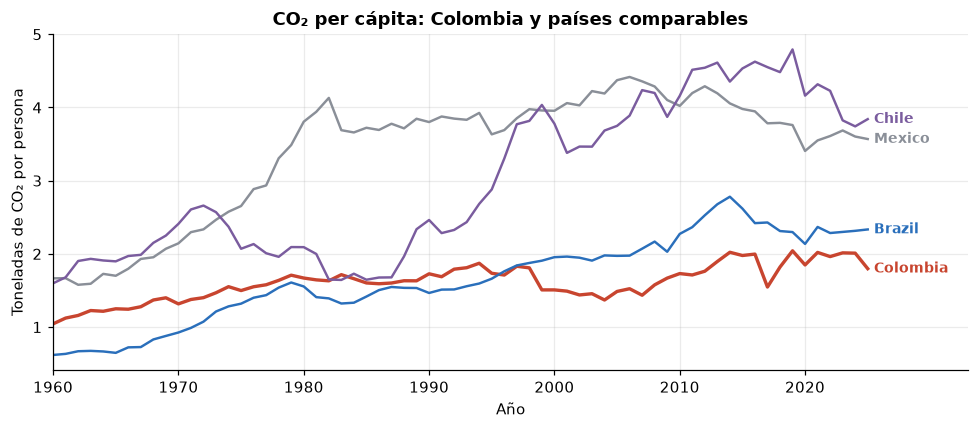

In [4]:
selec = {"Colombia": ROJO, "Brazil": AZUL, "Mexico": GRIS, "Chile": "#7a5c9e"}
serie = df[df["country"].isin(selec) & (df["year"] >= 1960)]

fig, ax = plt.subplots(figsize=(9, 4))
for pais, color in selec.items():
    s = serie[serie["country"] == pais]
    ax.plot(s["year"], s["co2_per_capita"], color=color, lw=2.2 if pais == "Colombia" else 1.6)
    ax.text(s["year"].iloc[-1] + 0.5, s["co2_per_capita"].iloc[-1], pais, color=color,
            va="center", fontsize=9, fontweight="bold")
ax.set_title("CO₂ per cápita: Colombia y países comparables")
ax.set_ylabel("Toneladas de CO₂ por persona")
ax.set_xlabel("Año")
ax.set_xlim(1960, serie["year"].max() + 8)
ax.set_xticks(range(1960, 2030, 10))
plt.tight_layout(); plt.show()

**Lectura:** Colombia emite por persona bastante menos que Chile y México y algo menos que Brasil, y su nivel se ha mantenido relativamente estable desde los años 90.

## 2.4 Distribución de las variables

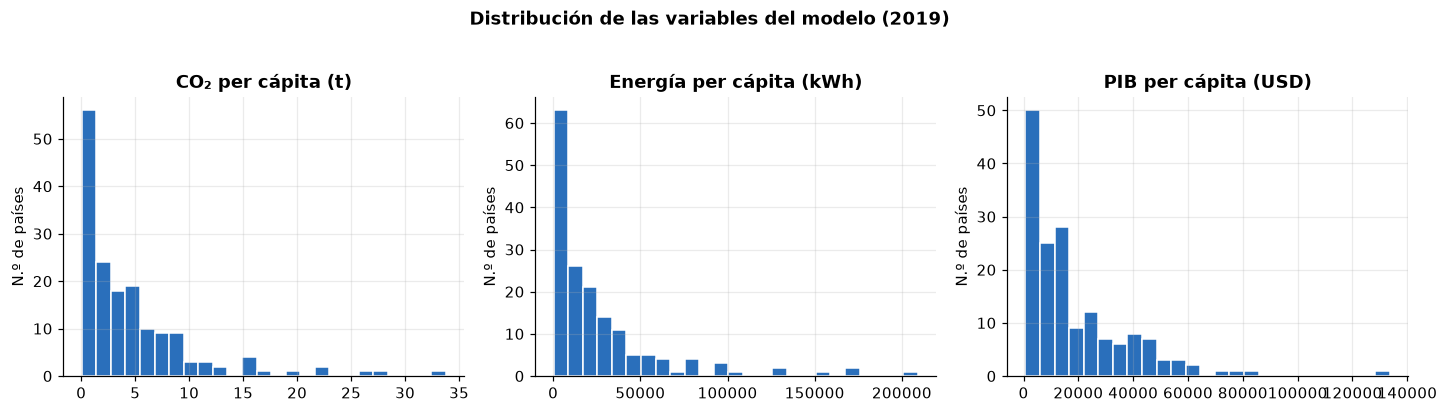

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, titulo in zip(axes, ["co2_per_capita", "energy_per_capita", "gdp_per_capita"],
                           ["CO₂ per cápita (t)", "Energía per cápita (kWh)", "PIB per cápita (USD)"]):
    ax.hist(limpio[col], bins=25, color=AZUL, edgecolor="white")
    ax.set_title(titulo); ax.set_ylabel("N.º de países")
plt.suptitle(f"Distribución de las variables del modelo ({ANIO})", y=1.03, fontweight="bold")
plt.tight_layout(); plt.show()